<a href="https://colab.research.google.com/github/techloul6018/Lab_Legland_GeneticAlgo/blob/main/lab1_madelon_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 – Evolutionary feature selection on Madelon

**Evolutionary Machine Learning · S. Ben Hamida · IAD-5 ESILV · 2026-2027 · 3 hours · Google Colab**

### The dataset
**Madelon** comes from the NIPS 2003 feature selection challenge (UCI 171, OpenML 1485). It is an artificial binary problem:
2,600 examples and **500 features**: **5 informative** features, **15 redundant** features (linear combinations of the 5), and **480 probes** with no predictive power.
The class depends on **combinations** of the informative features (the points are clusters on the vertices of a 5-dimensional hypercube).

### The goal
Compare classic feature selection with a genetic algorithm (`GAFeatureSelectionCV`), **honestly**: same model, same test set, known budget, several seeds.

### Plan (3 hours)
| Part | Time | Content | Lecture concepts |
|---|---|---|---|
| 0 | 15 min | Setup and data | encoding, size of the search space |
| A | 30 min | Classic baselines: filter, wrapper | filter / wrapper / embedded |
| B | 30 min | GA on the 500 features | population, budget, initialisation |
| C | 30 min | Two-stage search: filter, then GA, 3 seeds | randomness, several runs |
| D | 30 min | Exploration vs exploitation | mutation, tournament, population size |
| E | 25 min | Fair comparison and data leakage | budget, selection bias |
| F | 20 min | Synthesis | — |

**Rules.** Keep the same split and the same model (KNN, k = 5) everywhere, so that only the selected features change.
Answer the questions **Q0 to Q9** in the *Your answer* cells (total: 20 points). Code cells marked `TODO` must be completed.

## Part 0 – Setup and data (15 min)

In [ ]:
!pip install -q sklearn-genetic-opt

In [ ]:
import random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE
from sklearn_genetic import GAFeatureSelectionCV
from sklearn_genetic.callbacks import ConsecutiveStopping
from sklearn_genetic.plots import plot_fitness_evolution

warnings.filterwarnings("ignore")
SEED = 0
print("Ready.")

Ready.


In [ ]:
madelon = fetch_openml(data_id=1485, as_frame=False, parser="auto")   # Madelon, about 10 MB
X = madelon.data.astype(float)
y = LabelEncoder().fit_transform(madelon.target)
N_FEATURES = X.shape[1]
print("X:", X.shape, "| classes:", np.bincount(y))

X: (2600, 500) | classes: [1300 1300]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

**Q0. An individual of the GA is a binary mask over the features. How many different individuals exist for Madelon? Can we test them all?**

*Your answer:* 2^500 ≈ 3.3·10^150 masks (2^500 − 1 non-empty). Far too many to test: even at 10^9 evaluations per second it would take longer than the age of the universe, so we need a heuristic search.

Helper used in the whole lab: it trains KNN on the selected columns and measures the accuracy **once** on the test set.
`fits` is the number of model trainings used by the selection method (its budget).

In [ ]:
results = []

def report(method, mask, seconds, fits):
    mask = np.asarray(mask, dtype=bool)
    knn = KNeighborsClassifier().fit(X_train[:, mask], y_train)
    results.append({"method": method, "features": int(mask.sum()),
                    "test accuracy": round(knn.score(X_test[:, mask], y_test), 3),
                    "time (s)": round(seconds, 1), "model fits": fits})
    return results[-1]

def mask_from_columns(columns):
    """Build a 500-long boolean mask from a list of column indices."""
    m = np.zeros(N_FEATURES, dtype=bool); m[np.asarray(columns)] = True
    return m

## Part A – Classic baselines (30 min)

A.1 is already written. Then complete the filters and the wrapper.

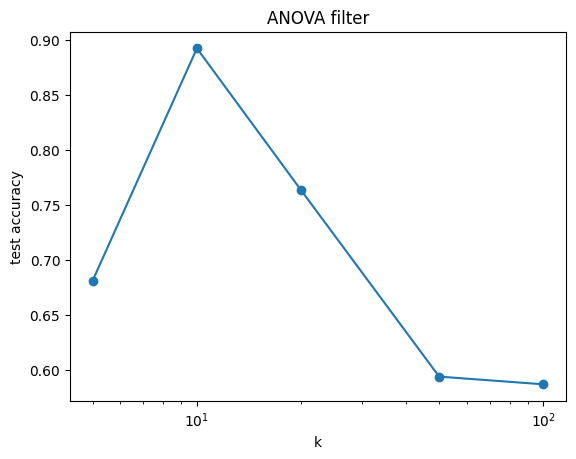

,method,features,test accuracy,time (s),model fits
0,All 500 features,500,0.532,0.0,0
1,ANOVA k=5,5,0.681,0.0,0
2,ANOVA k=10,10,0.892,0.0,0
3,ANOVA k=20,20,0.763,0.0,0
4,ANOVA k=50,50,0.594,0.0,0
5,ANOVA k=100,100,0.587,0.0,0
6,MI k=20,20,0.595,4.4,0
7,RFE k=20,20,0.829,6.7,48


In [ ]:
# A.1 – All features (already written)
t = time.time(); report("All 500 features", np.ones(N_FEATURES, bool), time.time() - t, fits=0)

# A.2 – ANOVA filter
anova_acc = {}
for k in [5, 10, 20, 50, 100]:
    t = time.time(); m = SelectKBest(f_classif, k=k).fit(X_train, y_train).get_support()
    anova_acc[k] = report(f"ANOVA k={k}", m, time.time() - t, fits=0)["test accuracy"]

# A.3 – Mutual information filter
t = time.time(); m = SelectKBest(mutual_info_classif, k=20).fit(X_train, y_train).get_support()
report("MI k=20", m, time.time() - t, fits=0)

# A.4 – RFE wrapper: 500 -> 20 by steps of 10 = 48 fits
t = time.time(); m = RFE(LogisticRegression(max_iter=2000), n_features_to_select=20, step=10).fit(X_train, y_train).support_
report("RFE k=20", m, time.time() - t, fits=48)

# A.5 – Plot
plt.plot(list(anova_acc), list(anova_acc.values()), "o-"); plt.xscale("log")
plt.xlabel("k"); plt.ylabel("test accuracy"); plt.title("ANOVA filter"); plt.show()

pd.DataFrame(results)

**Q1. Describe the curve accuracy = f(k). Why is there an optimum? Which k would you choose, and on which data would you choose it?**

*Your answer:* Accuracy rises from k=5 to around k=10–20, then drops for k=50, 100. Small k misses some informative/redundant features; large k adds probes, which add noise to KNN distances (curse of dimensionality). So there is an optimum around k≈20 (5 informative + 15 redundant). k must be chosen by cross-validation on the training set, never on the test set.

**Q2. RFE ranks the features with the coefficients of a logistic regression, and then we evaluate a KNN. Why can this be a problem?**

*Your answer:* Logistic regression is linear: its coefficients measure linear, individual effects. Madelon's class depends on non-linear combinations (XOR-like hypercube vertices), so the informative features can have small coefficients and be removed. The ranking is made for a different model than the one we evaluate (KNN), so the selected subset is not optimal for KNN.

## Part B – A genetic algorithm on the 500 features (30 min)

We now use `GAFeatureSelectionCV`. **Fitness** = 3-fold CV accuracy of KNN on the training set.
Budget of one run: at most `population_size × generations` evaluations, each one = 3 KNN trainings.

B.1 – Complete the function `run_ga`. It will be used in all the next parts.

In [ ]:
def run_ga(X_tr, seed=SEED, population_size=30, generations=30, mutation_probability=0.1,
           tournament_size=3, max_features=None, verbose=False):
    """Run GAFeatureSelectionCV on X_tr and return (selector, seconds)."""
    random.seed(seed); np.random.seed(seed)
    selector = GAFeatureSelectionCV(estimator=KNeighborsClassifier(), cv=3, scoring="accuracy",
                                    population_size=population_size, generations=generations,
                                    crossover_probability=0.8, mutation_probability=mutation_probability,
                                    tournament_size=tournament_size, elitism=True, max_features=max_features,
                                    n_jobs=-1, verbose=verbose)
    t = time.time()
    selector.fit(X_tr, y_train, callbacks=ConsecutiveStopping(generations=5, metric="fitness"))
    return selector, time.time() - t

 gen evals           avg          best     div  unique  stag     mut   sel             events
---- ----- ------------- ------------- ------- ------- ----- ------- ----- ------------------
   0    30       0.53081       0.55825   0.506   1.000     0       -     - -                 
   1    60       0.54203       0.56814   0.469   0.867     0   0.100     3 dup=5             
   2    60       0.54956       0.56814   0.452   0.733     1   0.100     3 dup=5             
   3    60       0.55813       0.57747   0.419   0.700     0   0.100     3 dup=7             
   4    60       0.56647       0.58627   0.353   0.600     0   0.100     3 dup=4             
   5    60       0.57158       0.58902   0.263   0.600     0   0.100     3 dup=8             
   6    60       0.57685       0.59119   0.227   0.633     0   0.100     3 dup=10            
   7    60       0.58125       0.59177   0.152   0.633     0   0.200     3 div,imm=6,dup=2   
   8    60       0.58162       0.59231   0.101   0.733     0

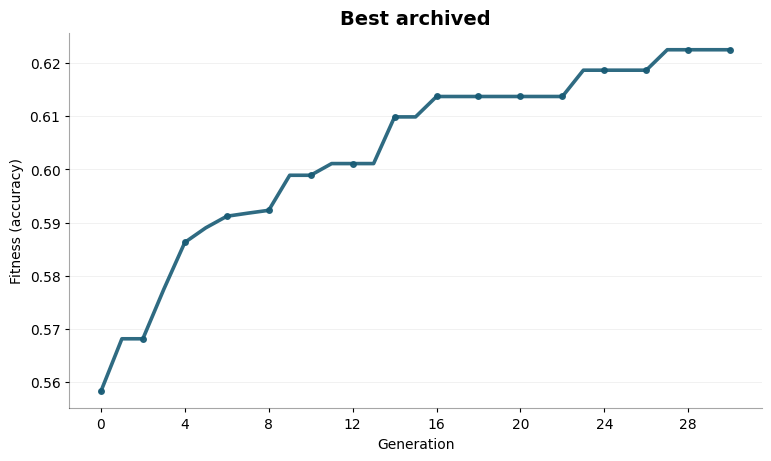

In [ ]:
sel, s = run_ga(X_train, verbose=True)
print(report("GA 500 features", sel.support_, s, fits=30 * 30 * 3))
plot_fitness_evolution(sel); plt.show()

**Q3. How many features does the GA keep, and how good is it compared with the filter? Explain this result with the lecture: initial population, size of the search space, budget.**

*Your answer:* The GA keeps a lot of features (around half of the 500, ~250) and its test accuracy is much lower than the ANOVA filter (close to the all-features baseline). The initial population draws each bit at random, so individuals start with ~250 features. The space 2^500 is huge and the budget (≤900 evaluations) is tiny, so the GA cannot shrink the subsets down to the ~20 useful ones in 30 generations.

In [ ]:
sel, s = run_ga(X_train, max_features=20)
print(report("GA 500 features, max 20", sel.support_, s, fits=30 * 30 * 3))

{'method': 'GA 500 features, max 20', 'features': 5, 'test accuracy': 0.838, 'time (s)': 63.1, 'model fits': 2700}


**Q4. What does max_features change in the search? Is it a good idea when we do not know the number of useful features?**

*Your answer:* max_features bounds the subset size: initial individuals and offspring have at most 20 features, so the search starts in the right region of small subsets and the probability of picking good features rises. It helps a lot here, but only because we know there are ~20 useful features. If the true number is unknown, a wrong bound can exclude the optimum (too small) or be useless (too large); it should be tuned or validated.

## Part C – Two-stage search: filter, then GA (30 min)

Idea: a cheap **filter** removes most probes, then the **GA** searches inside the 50 best features.
The GA now works on a space of 2^50 masks instead of 2^500.

INFO: ConsecutiveStopping callback met its criteria
INFO: Stopping the algorithm
{'method': 'ANOVA50 + GA seed 0', 'features': 13, 'test accuracy': 0.862, 'time (s)': 30.7, 'model fits': 2700}


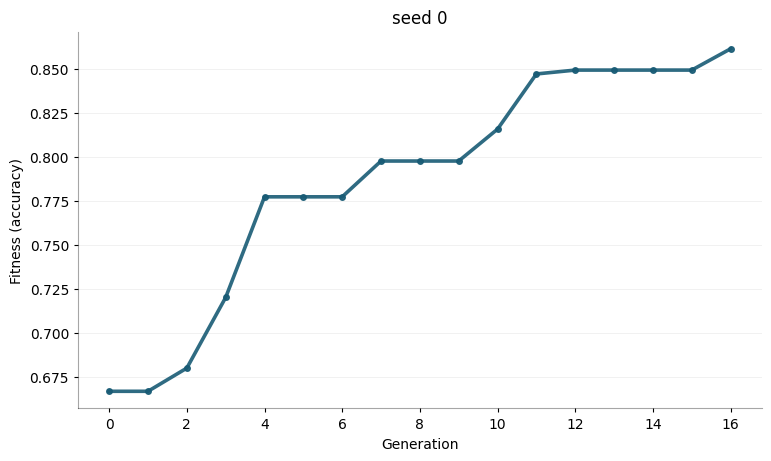

{'method': 'ANOVA50 + GA seed 1', 'features': 15, 'test accuracy': 0.826, 'time (s)': 43.4, 'model fits': 2700}


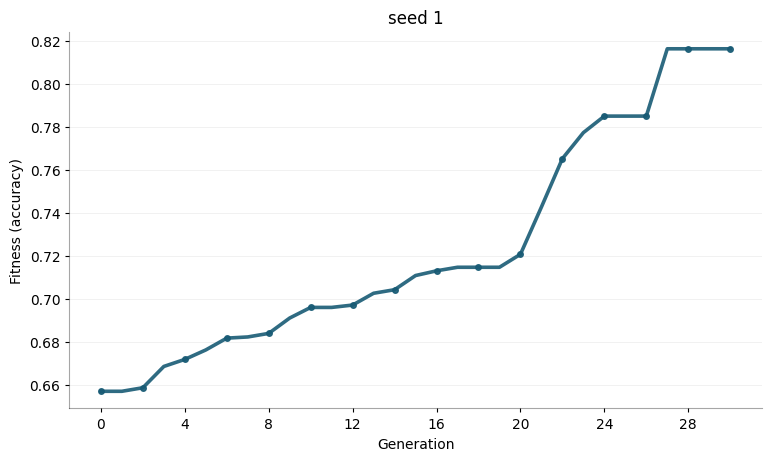

INFO: ConsecutiveStopping callback met its criteria
INFO: Stopping the algorithm
{'method': 'ANOVA50 + GA seed 2', 'features': 15, 'test accuracy': 0.824, 'time (s)': 25.9, 'model fits': 2700}


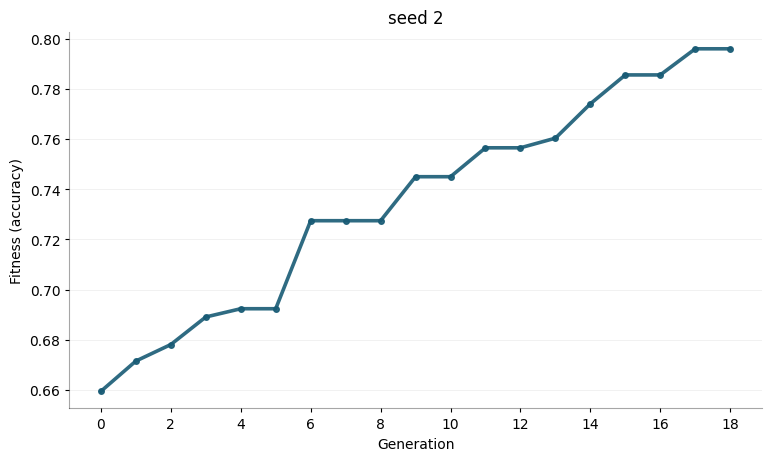

In [ ]:
F, _ = f_classif(X_train, y_train)
top50 = np.argsort(F)[::-1][:50]
X_train50 = X_train[:, top50]
two_stage = {}
for seed in [0, 1, 2]:
    sel, s = run_ga(X_train50, seed=seed)
    two_stage[seed] = top50[sel.support_]
    print(report(f"ANOVA50 + GA seed {seed}", mask_from_columns(two_stage[seed]), s, fits=30 * 30 * 3))
    plot_fitness_evolution(sel); plt.title(f"seed {seed}"); plt.show()

In [ ]:
sets = [set(v) for v in two_stage.values()]
print("sizes:", [len(s) for s in sets])
print("in all three:", sorted(set.intersection(*sets)))
print("in at least one:", sorted(set.union(*sets)))

sizes: [13, 15, 15]
in all three: [np.int64(48), np.int64(64), np.int64(105), np.int64(128), np.int64(241), np.int64(338), np.int64(378), np.int64(442), np.int64(453), np.int64(472), np.int64(475)]
in at least one: [np.int64(18), np.int64(41), np.int64(48), np.int64(64), np.int64(83), np.int64(105), np.int64(128), np.int64(196), np.int64(241), np.int64(336), np.int64(338), np.int64(378), np.int64(424), np.int64(442), np.int64(445), np.int64(453), np.int64(472), np.int64(475), np.int64(493)]


**Q5. Do the three runs give the same subset and the same accuracy? What does it mean for the way you report a result?**

*Your answer:* No: the three seeds give different subsets (a common core of strong features, plus different extra ones) and slightly different accuracies. The GA is stochastic, so one run is not a result: report the mean ± std over several seeds, the budget, and the stability of the selected features.

## Part D – Exploration vs exploitation (30 min)

Work on the two-stage problem (`X_train50`). Change **one parameter at a time** from the default
(population 30, mutation 0.1, tournament 3), seed 0. Note the best CV fitness, the number of features and the test accuracy.

INFO: ConsecutiveStopping callback met its criteria
INFO: Stopping the algorithm
INFO: ConsecutiveStopping callback met its criteria
INFO: Stopping the algorithm
INFO: ConsecutiveStopping callback met its criteria
INFO: Stopping the algorithm


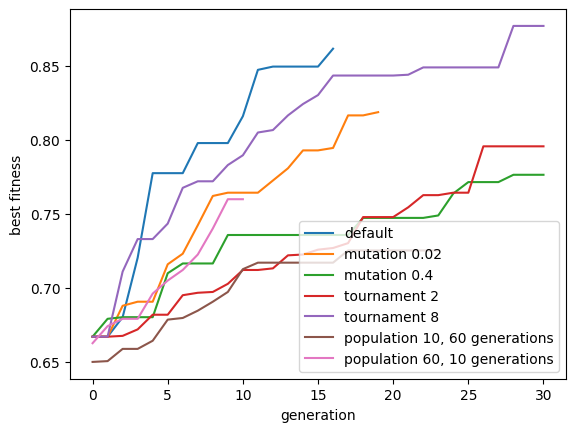

,setting,best CV,features,test accuracy,time (s)
0,default,0.862,13,0.862,30.9
1,mutation 0.02,0.819,15,0.832,27.6
2,mutation 0.4,0.776,19,0.762,41.1
3,tournament 2,0.796,16,0.827,42.0
4,tournament 8,0.877,11,0.886,53.3
5,"population 10, 60 generations",0.725,29,0.679,11.2
6,"population 60, 10 generations",0.760,17,0.756,33.7


In [ ]:
settings = {"default": {},
            "mutation 0.02": {"mutation_probability": 0.02},
            "mutation 0.4": {"mutation_probability": 0.4},
            "tournament 2": {"tournament_size": 2},
            "tournament 8": {"tournament_size": 8},
            "population 10, 60 generations": {"population_size": 10, "generations": 60},
            "population 60, 10 generations": {"population_size": 60, "generations": 10}}
study = []
for name, kw in settings.items():
    sel, s = run_ga(X_train50, seed=0, **kw)
    r = report(f"Part D {name}", mask_from_columns(top50[sel.support_]), s, fits=30 * 30 * 3)
    study.append({"setting": name, "best CV": round(sel.best_score_, 3), "features": r["features"],
                  "test accuracy": r["test accuracy"], "time (s)": r["time (s)"]})
    plt.plot(sel.history["fitness_max"], label=name)
plt.xlabel("generation"); plt.ylabel("best fitness"); plt.legend(); plt.show()

pd.DataFrame(study)

**Q6. Using your table and curves, explain the effect of (a) the mutation probability, (b) the tournament size, (c) the population size at a fixed budget, in terms of exploration and exploitation.**

*Your answer:* (a) Low mutation (0.02) = strong exploitation, fast convergence but risk of being stuck early; high mutation (0.4) = more exploration but behaves closer to random search and converges slowly/noisily. (b) Tournament 2 = low selection pressure, more diversity (exploration), slower progress; tournament 8 = high pressure, the best dominate quickly (exploitation), risk of premature convergence. (c) At a fixed budget, small population/many generations exploits more (deep but narrow search, less diversity); large population/few generations explores more (wide but not enough generations to refine).

## Part E – Fair comparison and data leakage (25 min)

**E.1 Same budget.** Is the GA better than a **random search** that tests the same number of random subsets?
Complete `random_subset_search`: it draws random masks over the 50 columns (each feature kept with probability 0.3),
computes the same fitness, and keeps the best one. Use the same number of evaluations as one GA run (600).

In [ ]:
def random_subset_search(X_tr, n_evals=600, p_keep=0.3, seed=SEED):
    rng = np.random.default_rng(seed); best_score, best_mask = -1, None
    for _ in range(n_evals):
        mask = rng.random(X_tr.shape[1]) < p_keep
        if not mask.any():
            continue
        score = cross_val_score(KNeighborsClassifier(), X_tr[:, mask], y_train, cv=3, scoring="accuracy").mean()
        if score > best_score:
            best_score, best_mask = score, mask
    return best_mask, best_score

for seed in [0, 1, 2]:
    t = time.time(); m, sc = random_subset_search(X_train50, seed=seed)
    print(report(f"ANOVA50 + random search seed {seed}", mask_from_columns(top50[m]), time.time() - t, fits=600 * 3))

{'method': 'ANOVA50 + random search seed 0', 'features': 10, 'test accuracy': 0.786, 'time (s)': 36.4, 'model fits': 1800}
{'method': 'ANOVA50 + random search seed 1', 'features': 13, 'test accuracy': 0.746, 'time (s)': 35.6, 'model fits': 1800}
{'method': 'ANOVA50 + random search seed 2', 'features': 11, 'test accuracy': 0.755, 'time (s)': 34.6, 'model fits': 1800}


**Q7. Compare the GA (Part C) and the random search at the same budget. What do you conclude? In which situation would you expect the GA to win clearly?**

*Your answer:* On the 50 pre-filtered features, random search reaches an accuracy close to the GA at the same budget: the filter already did most of the work and the space is small enough that random sampling finds good subsets. The GA is not clearly better here. It should win clearly when the space is large and structured (many features, few useful ones, interactions) where building on good partial solutions via selection/crossover matters, and when the budget is large enough for many generations.

**E.2 Data leakage.** We build a dataset with **no signal at all** (pure noise, random labels), and we compare two protocols:
* **leaky**: select the 10 "best" features on all the data, then cross-validate the model;
* **honest**: put the selection **inside** the cross-validation (a `Pipeline`).

In [ ]:
from sklearn.pipeline import make_pipeline
leaky, honest = [], []
for seed in range(5):
    rng = np.random.default_rng(seed)
    Xn = rng.normal(size=(100, 500)); yn = rng.integers(0, 2, 100)
    Xs = SelectKBest(f_classif, k=10).fit_transform(Xn, yn)
    leaky.append(cross_val_score(KNeighborsClassifier(), Xs, yn, cv=5).mean())
    honest.append(cross_val_score(make_pipeline(SelectKBest(f_classif, k=10), KNeighborsClassifier()), Xn, yn, cv=5).mean())
print("leaky :", np.round(leaky, 2), "mean", round(np.mean(leaky), 2))
print("honest:", np.round(honest, 2), "mean", round(np.mean(honest), 2))

leaky : [0.64 0.77 0.72 0.75 0.72] mean 0.72
honest: [0.51 0.64 0.56 0.55 0.41] mean 0.53


**Q8. The data has no signal, yet the leaky protocol gives about 70 % accuracy. Explain why. How does this apply to a GA that selects features with cross-validation?**

*Your answer:* In the leaky protocol, the 10 features are chosen using all the labels, including those of the future validation folds: by chance some noise features correlate with yn on this sample, and CV then measures that chance correlation, giving ~70%. The honest pipeline re-selects inside each training fold, so the validation fold is unseen and the score drops to ~50%. For a GA: its CV fitness is maximised over hundreds of subsets, so best_score_ is optimistically biased (selection bias). The selection must be evaluated on an independent test set (or nested CV), as we do with report().

## Part F – Synthesis (20 min)

,method,features,test accuracy,time (s),model fits
2,ANOVA k=10,10,0.892,0.0,0
10,ANOVA50 + GA seed 0,13,0.862,30.7,2700
9,"GA 500 features, max 20",5,0.838,63.1,2700
7,RFE k=20,20,0.829,6.7,48
11,ANOVA50 + GA seed 1,15,0.826,43.4,2700
12,ANOVA50 + GA seed 2,15,0.824,25.9,2700
20,ANOVA50 + random search seed 0,10,0.786,36.4,1800
3,ANOVA k=20,20,0.763,0.0,0
22,ANOVA50 + random search seed 2,11,0.755,34.6,1800
21,ANOVA50 + random search seed 1,13,0.746,35.6,1800


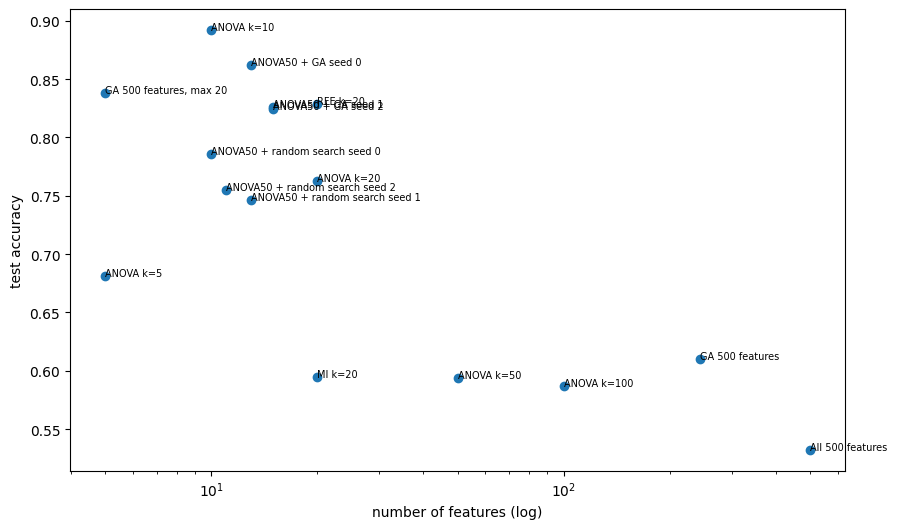

In [ ]:
summary = pd.DataFrame(results)
summary = summary[~summary["method"].str.startswith("Part D")]
display(summary.sort_values("test accuracy", ascending=False))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(summary["features"], summary["test accuracy"])
for _, r in summary.iterrows():
    ax.annotate(r["method"], (r["features"], r["test accuracy"]), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("number of features (log)"); ax.set_ylabel("test accuracy"); plt.show()

**Q9. In about 8 lines: which approach would you recommend for a dataset like Madelon, with which settings, and how would you report the result to a colleague?**

*Your answer:* For Madelon I recommend a two-stage approach: a cheap ANOVA filter (top 50) to remove most probes, then a GA (population 30, 30 generations, mutation ~0.1, tournament 3, elitism, early stopping) with KNN as the fitness model, or simply a filter with k chosen by CV if the budget is tight. The selection must be done only on the training data (inside CV) to avoid leakage. I would run several seeds (≥3–5), and report the mean ± std of the test accuracy on a held-out test set, the number of features, the budget (model fits) and time, and compare with baselines at the same budget (filter, random search). I would also report the stability of the selected features across seeds. Never report the best CV fitness of the GA as the final performance.

### Bonus (for fast groups)
1. Replace KNN by `SVC()` in `run_ga` **and** in `report`. Does the GA select the same features? Why can a wrapper select different features for a different model?
2. Run Part C with mutual information instead of ANOVA for the first stage.
3. Run the GA of Part B with `population_size=60, generations=40` (about 4 times the budget). How much does it improve, and how much longer does it take?